=== THE GUARDIAN: DESCRIPTIVE STATISTICS ===
Total Articles Scraped: 5
Valid Articles Analyzed: 5
Missing/Failed Data Rate: 0.00%



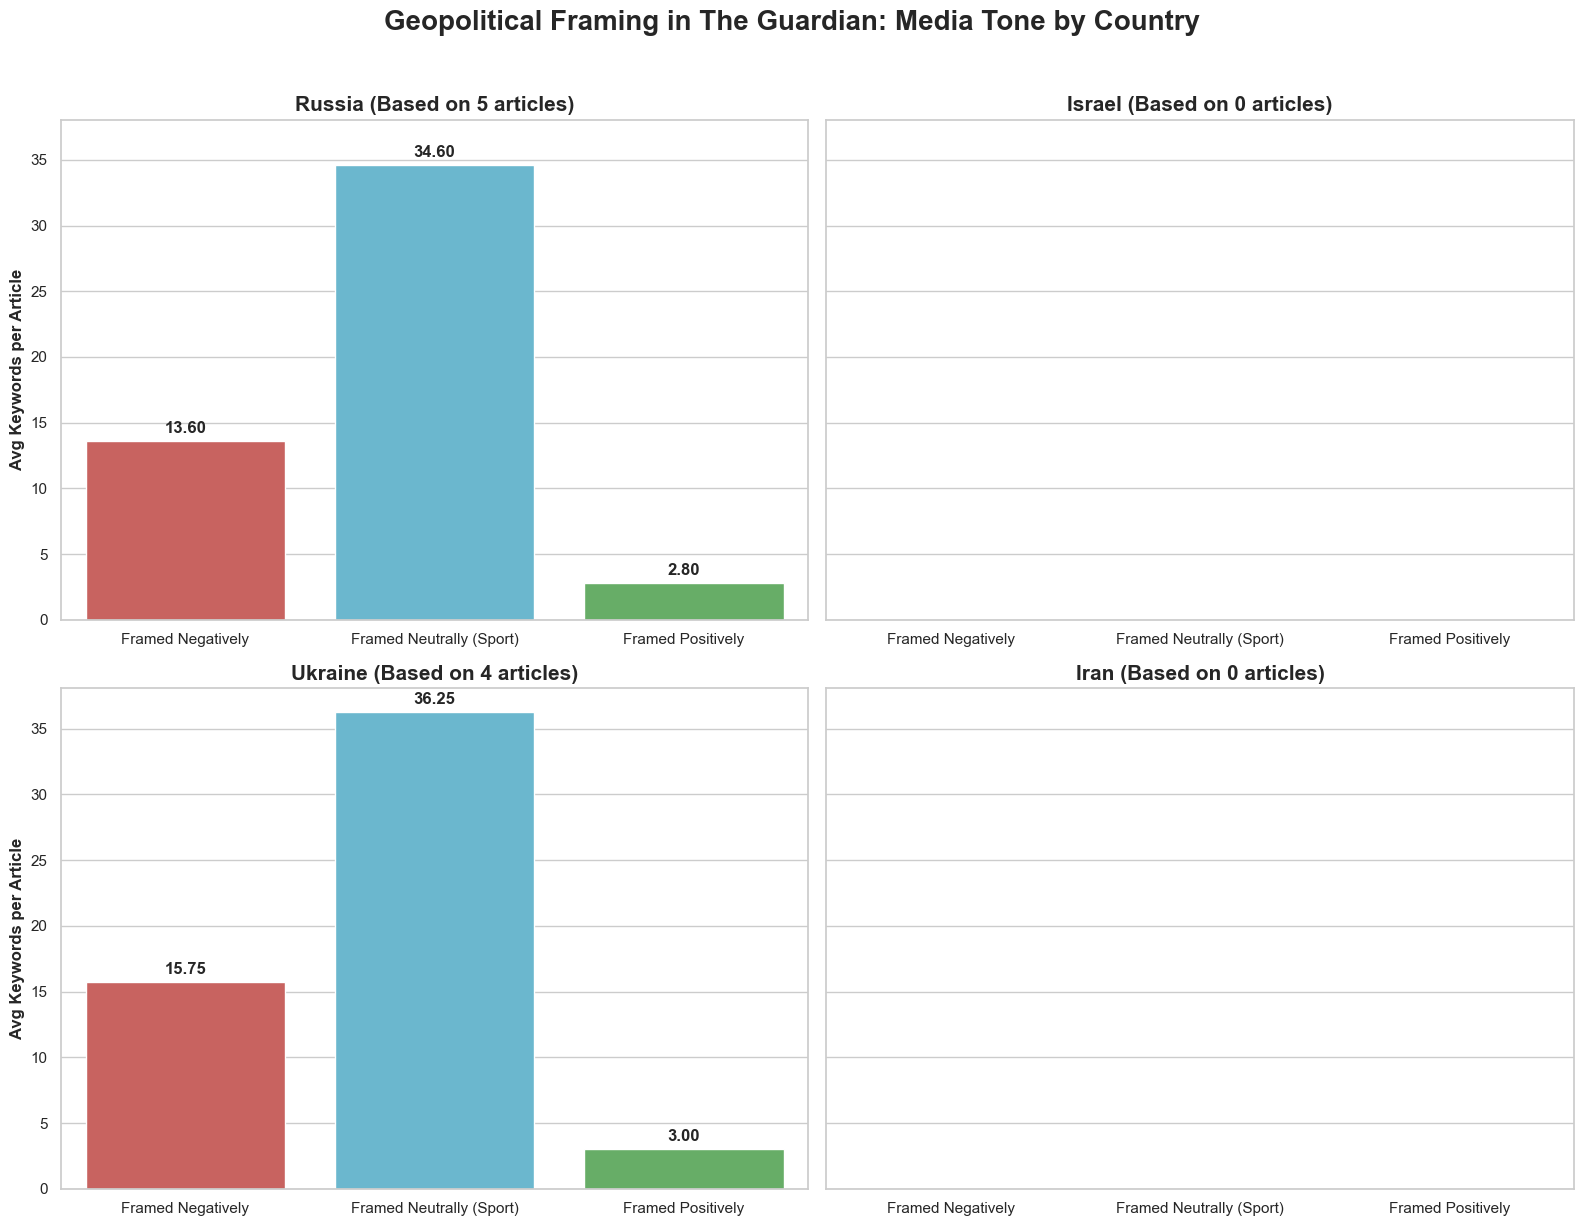

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# 1. Keyword Buckets
framing_buckets = {
    "Framed Negatively": [
        "sanction", "sanctions", "ban", "banned", "war", "conflict", "invasion",
        "tension", "geopolitical", "controversy", "controversial", "protest", 
        "boycott", "violation", "dispute", "restriction", "suspension", 
        "propaganda", "crisis", "disqualification", "disqualified", "aggression", 
        "condemn", "bad", "terrible", "threat", "hostile", "escalate", 
        "escalation", "authoritarian", "regime", "unprovoked", "breach", 
        "atrocity", "unlawful", "illicit", "retaliation", "punitive", 
        "isolation", "isolated", "exclusion", "excluded", "doping", 
        "scandal", "corruption", "dissent", "alienation"
    ],
    "Framed Neutrally (Sport)": [
        "athlete", "athletes", "competition", "compete", "competing",
        "performance", "perform", "medal", "gold", "silver", "bronze",
        "event", "race", "match", "training", "coach", "qualification",
        "qualify", "team", "score", "result", "season", "final", "win", 
        "victory", "championship", "tournament", "standings", "podium"
    ],
    "Framed Positively": [
        "success", "successful", "hope", "hopeful", "peace", "unity", 
        "triumph", "support", "resilience", "overcome", "proud", 
        "solidarity", "celebration", "courage", "inspiring", "fairness",
        "diplomatic", "diplomacy", "truce", "reconciliation", "integration", 
        "welcome", "welcomed", "achievement", "perseverance", "harmony", 
        "cooperation", "goodwill", "heroic", "historic", "breakthrough", 
        "fair play", "sportsmanship", "camaraderie"
    ]
}

country_keywords = {
    "Russia": ["russia", "russian", "moscow", "ain", "neutral athlete"],
    "Israel": ["israel", "israeli", "tel aviv"],
    "Ukraine": ["ukraine", "ukrainian", "kyiv"],
    "Iran": ["iran", "iranian", "tehran"]
}

# 2. Load The Guardian Data
try:
    with open('Articles.json', 'r', encoding='utf-8') as f:
        guardian_data = json.load(f)
except FileNotFoundError:
    print("Error: Could not find 'Articles.json'.")
    guardian_data = []

# 3. Print Descriptive Statistics & Data Health
total_urls = len(guardian_data)
valid_articles = sum(1 for article in guardian_data if len(article.get("Article_Text", "")) > 50)
missing_rate = ((total_urls - valid_articles) / total_urls) * 100 if total_urls > 0 else 0

print("=== THE GUARDIAN: DESCRIPTIVE STATISTICS ===")
print(f"Total Articles Scraped: {total_urls}")
print(f"Valid Articles Analyzed: {valid_articles}")
print(f"Missing/Failed Data Rate: {missing_rate:.2f}%\n")

# 4. Setup tracking dictionaries
guardian_stats = {country: {"Article_Count": 0, "Frames": {frame: 0 for frame in framing_buckets}} for country in country_keywords}

# 5. Sort and Analyze the Articles
for article in guardian_data:
    text = article.get("Article_Text", "").lower()
    
    for country, keywords in country_keywords.items():
        if any(kw in text for kw in keywords):
            guardian_stats[country]["Article_Count"] += 1
            for frame_name, frame_words in framing_buckets.items():
                for word in frame_words:
                    guardian_stats[country]["Frames"][frame_name] += text.count(word.lower())

# 6. Calculate Averages
plot_data = []
for country, data in guardian_stats.items():
    count = data["Article_Count"]
    if count > 0:
        for frame, total in data["Frames"].items():
            plot_data.append({"Country": country, "Framing Type": frame, "Average Mentions": total / count})
    else:
        for frame in framing_buckets:
             plot_data.append({"Country": country, "Framing Type": frame, "Average Mentions": 0.0})

df_guardian_plot = pd.DataFrame(plot_data)

# 7. Generate the 2x2 Grid
sns.set_theme(style="whitegrid")
custom_colors = ["#d9534f", "#5bc0de", "#5cb85c"] 

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
fig.suptitle('Geopolitical Framing in The Guardian: Media Tone by Country', fontsize=20, fontweight='bold', y=1.02)
axes = axes.flatten()

countries = list(country_keywords.keys())

for i, country in enumerate(countries):
    country_data = df_guardian_plot[df_guardian_plot["Country"] == country]
    ax = sns.barplot(data=country_data, x="Framing Type", y="Average Mentions", hue="Framing Type", palette=custom_colors, legend=False, ax=axes[i])
    
    article_count = guardian_stats[country]["Article_Count"]
    axes[i].set_title(f'{country} (Based on {article_count} articles)', fontsize=15, fontweight='bold')
    axes[i].set_xlabel('')
    
    if i % 2 == 0: 
        axes[i].set_ylabel('Avg Keywords per Article', fontsize=12, fontweight='bold')
    else:
        axes[i].set_ylabel('')
        
    for p in ax.patches:
        height = p.get_height()
        if height > 0: 
            ax.annotate(f'{height:.2f}', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### The Guardian: Preliminary Observations & Anomalies

* **Observation:** The Guardian yielded the smallest dataset by far, with only 5 valid articles scraped (0% missing data). The coverage is entirely restricted to Eastern Europe, with Russia appearing in 5 articles and Ukraine in 4, while Israel and Iran yielded absolutely zero results. Even within this limited scope, neutral sports terms remain the most frequent category.
* **Anomaly:** The keyword distributions for Russia and Ukraine are nearly identical in shape and averages (e.g., ~13-15 negative words and ~34-36 neutral words). Because the total volume is so  low, this mirroring effect strongly indicates that the exact same articles are discussing both nations simultaneously, completely intertwining their data.